# 06 — Reducing the number of categories + checking the ECI/PCI patterns

Uses the files saved by the previous notebooks (`tract_category_counts_top50.parquet`, `eci_per_city_top50.parquet`, `eci_pooled_top50.parquet`).

**Part 1 — fewer categories.** Drop categories that
(a) are present in fewer than `MIN_CITIES` of the 50 cities, and/or
(b) have fewer than `MIN_POIS` POIs across the 50 cities,
and see how this changes the ECI.

**Part 2 — how similar are the patterns?**
1. correlation between amenity complexity (PCI) and ubiquity, in each city
2. correlation between the single-city ECI and the pooled ECI
3. correlation between the single-city PCI and the pooled PCI

In [2]:
# ── imports ───────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from ecomplexity import ecomplexity

# ── font sizes ────────────────────────────────────────────────────────────────
FS = 10
FS2 = FS - 2
FS4 = FS - 4

# ── paths ─────────────────────────────────────────────────────────────────────
PROCESSED = "C:/Users/pc/Downloads/data/processed/"

# ── city shown in the single-city plots ───────────────────────────────────────
CBSA = "14460"      # Boston

## 0. Load data

In [3]:
# LOAD
all_counts = pd.read_parquet(PROCESSED + "tract_category_counts_top50.parquet")
all_counts["cbsacode"] = all_counts["cbsacode"].astype(str)

N_CITIES = all_counts["cbsacode"].nunique()
print(f"Rows: {len(all_counts)}, cities: {N_CITIES}, categories: {all_counts['POI_clean_category'].nunique()}")

Rows: 2768225, cities: 50, categories: 410


In [4]:
# ── city names (for the plots) ───────────────────────────────────────────────
NAMES = {
    "35620": "New York", "31080": "Los Angeles", "16980": "Chicago", "19100": "Dallas-Fort Worth",
    "26420": "Houston", "47900": "Washington DC", "37980": "Philadelphia", "33100": "Miami",
    "12060": "Atlanta", "14460": "Boston", "38060": "Phoenix", "41860": "San Francisco",
    "40140": "Riverside", "19820": "Detroit", "42660": "Seattle", "33460": "Minneapolis",
    "41740": "San Diego", "45300": "Tampa", "19740": "Denver", "12580": "Baltimore",
    "41180": "St. Louis", "36740": "Orlando", "16740": "Charlotte", "41700": "San Antonio",
    "38900": "Portland", "40900": "Sacramento", "38300": "Pittsburgh", "12420": "Austin",
    "29820": "Las Vegas", "17140": "Cincinnati", "28140": "Kansas City", "18140": "Columbus",
    "26900": "Indianapolis", "17460": "Cleveland", "41940": "San Jose", "34980": "Nashville",
    "47260": "Virginia Beach", "39300": "Providence", "33340": "Milwaukee", "27260": "Jacksonville",
    "36420": "Oklahoma City", "39580": "Raleigh", "32820": "Memphis", "40060": "Richmond",
    "31140": "Louisville", "35380": "New Orleans", "41620": "Salt Lake City", "25540": "Hartford",
    "15380": "Buffalo", "13820": "Birmingham",
}
def city_name(cbsa):
    return NAMES.get(cbsa, cbsa)

## Helper functions

In [5]:
# ── statistics per category: in how many cities, and how many POIs ───────────
def category_stats(counts):
    g = counts.groupby("POI_clean_category")
    return pd.DataFrame({"n_cities": g["cbsacode"].nunique(),
                         "n_pois": g["nr_amenities"].sum()})


# ── keep only categories present in >= min_cities cities and with >= min_pois POIs
def filter_categories(counts, min_cities, min_pois):
    stats = category_stats(counts)
    keep = stats[(stats["n_cities"] >= min_cities) & (stats["n_pois"] >= min_pois)].index
    return counts[counts["POI_clean_category"].isin(keep)]


# ── ECI (tracts) and PCI + ubiquity (categories) for each city separately ─────
def complexity_by_city(counts):
    eci_list, cat_list = [], []
    for cbsa, group in counts.groupby("cbsacode"):
        df = group[["census_tract_ID", "POI_clean_category", "nr_amenities"]].copy()
        df["time"] = 0                                     # one snapshot -> dummy time variable
        cols_input = {"time": "time", "loc": "census_tract_ID",
                      "prod": "POI_clean_category", "val": "nr_amenities"}
        try:
            res = ecomplexity(df, cols_input, check_logsupermodularity=False, verbose=False)
        except Exception as ex:
            print(f"{city_name(cbsa)}: ECI failed ({ex})")
            continue
        eci_list.append(res[["census_tract_ID", "diversity", "eci"]].drop_duplicates().assign(cbsacode=cbsa))
        cat_list.append(res[["POI_clean_category", "ubiquity", "pci"]].drop_duplicates().assign(cbsacode=cbsa))
    return pd.concat(eci_list, ignore_index=True), pd.concat(cat_list, ignore_index=True)


# ── Spearman correlation of the ECI of two versions, city by city ─────────────
def compare_eci(a, b):
    m = a.merge(b, on=["census_tract_ID", "cbsacode"], suffixes=("_a", "_b"))
    rows = {}
    for cbsa, g in m.groupby("cbsacode"):
        rows[cbsa] = spearmanr(g["eci_a"], g["eci_b"])[0]
    return pd.Series(rows)

## Part 1. Fewer categories

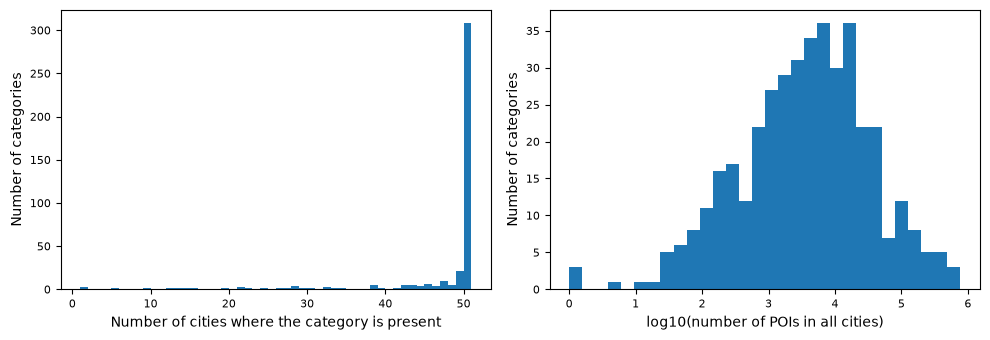

In [6]:
# ── how are the categories distributed? ──────────────────────────────────────
stats = category_stats(all_counts)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(stats["n_cities"], bins=range(1, N_CITIES + 2), color="tab:blue")
axes[0].set_xlabel("Number of cities where the category is present", fontsize=FS)
axes[0].set_ylabel("Number of categories", fontsize=FS)
axes[1].hist(np.log10(stats["n_pois"]), bins=30, color="tab:blue")
axes[1].set_xlabel("log10(number of POIs in all cities)", fontsize=FS)
axes[1].set_ylabel("Number of categories", fontsize=FS)
for ax in axes:
    ax.tick_params(labelsize=FS2)
fig.tight_layout()

In [7]:
# ── how many categories (and POIs) are left for different thresholds? ────────
total_pois = all_counts["nr_amenities"].sum()
rows = []
for min_cities in [1, int(0.5 * N_CITIES), int(0.8 * N_CITIES), N_CITIES]:
    for min_pois in [0, 10, 25, 50, 200]:
        kept = filter_categories(all_counts, min_cities, min_pois)
        rows.append({"min_cities": min_cities, "min_pois": min_pois,
                     "n_categories": kept["POI_clean_category"].nunique(),
                     "share_of_pois": kept["nr_amenities"].sum() / total_pois})
thresholds = pd.DataFrame(rows)

print("Number of categories left:")
print(thresholds.pivot(index="min_cities", columns="min_pois", values="n_categories"))
print("\nShare of POIs kept:")
print(thresholds.pivot(index="min_cities", columns="min_pois", values="share_of_pois").round(3))

Number of categories left:
min_pois    0    10   25   50   200
min_cities                         
1           410  406  404  397  363
25          394  394  394  394  363
40          370  370  370  370  361
50          308  308  308  308  308

Share of POIs kept:
min_pois      0      10     25     50     200
min_cities                                   
1           1.000  1.000  1.000  1.000  1.000
25          1.000  1.000  1.000  1.000  1.000
40          1.000  1.000  1.000  1.000  1.000
50          0.996  0.996  0.996  0.996  0.996


In [8]:
# ── which categories would be removed? (example: present in < 80% of cities or < 50 POIs) ──
removed = stats[(stats["n_cities"] < int(0.8 * N_CITIES)) | (stats["n_pois"] < 50)]
print(f"{len(removed)} categories removed")
removed.sort_values("n_pois", ascending=False).head(20)

40 categories removed


,n_cities,n_pois
POI_clean_category,,
Baggage Locker,34,248
Disc Golf Course,32,224
Government Lobbyist,38,180
Geological Service,30,173
Picnic Shelter,39,156
Swimming Pool Supply Store,29,154
Duty-free Store,32,137
Meadery,39,132
Port,28,129


### How much does the ECI/PCI change?

We compute the ECI of every city with a few category sets and correlate each one with the baseline (all categories), tract by tract inside each city.
A correlation close to 1 means the filter hardly changes the ranking of the neighborhoods.

In [9]:
# ── scenarios: (min_cities, min_pois) ────────────────────────────────────────
SCENARIOS = {
    "≥ 80% of cities, ≥ 10 POIs": (int(0.8 * N_CITIES), 10),
    "≥ 80% of cities, ≥ 50 POIs": (int(0.8 * N_CITIES), 50),
    "all cities, ≥ 50 POIs":      (N_CITIES, 50),
}

# baseline = all categories (computed earlier in the first notebook)
baseline = pd.read_parquet(PROCESSED + "eci_per_city_top50.parquet")      # LOAD
baseline["cbsacode"] = baseline["cbsacode"].astype(str)

scenario_eci = {}
comparison = {}
for label, (min_cities, min_pois) in SCENARIOS.items():
    kept = filter_categories(all_counts, min_cities, min_pois)
    eci_s, _ = complexity_by_city(kept)
    scenario_eci[label] = eci_s
    comparison[label] = compare_eci(baseline, eci_s)
    print(f"{label}: {kept['POI_clean_category'].nunique()} categories, "
          f"median correlation with baseline = {comparison[label].median():.2f}")

comparison = pd.DataFrame(comparison)
comparison.index = [city_name(c) for c in comparison.index]
comparison.describe().loc[["mean", "50%", "min", "max"]].round(2)

≥ 80% of cities, ≥ 10 POIs: 370 categories, median correlation with baseline = 1.00
≥ 80% of cities, ≥ 50 POIs: 370 categories, median correlation with baseline = 1.00
all cities, ≥ 50 POIs: 308 categories, median correlation with baseline = 0.99


,"≥ 80% of cities, ≥ 10 POIs","≥ 80% of cities, ≥ 50 POIs","all cities, ≥ 50 POIs"
mean,0.99,0.99,0.98
50%,1.00,1.00,0.99
min,0.61,0.61,0.62
max,1.00,1.00,1.00


-> Filtering has very little effect on ECI rankings for most metros, although a few metros are more sensitive.

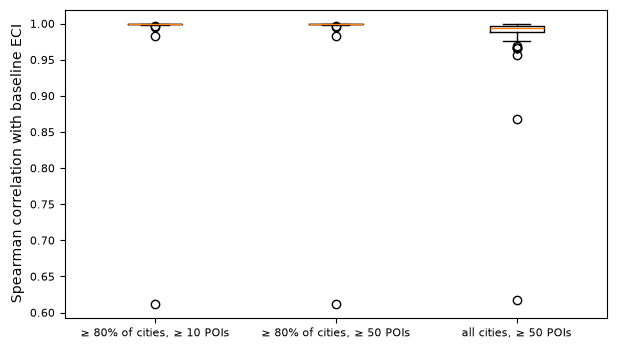

In [10]:
# ── plot: correlation with the baseline ECI, one box per scenario ────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([comparison[c].dropna() for c in comparison.columns])
ax.set_xticklabels(comparison.columns, fontsize=FS4)
ax.set_ylabel("Spearman correlation with baseline ECI", fontsize=FS)
ax.tick_params(labelsize=FS2)

In [11]:
# ── choose the working category specification based on robustness tests ───────────────────────────────
MIN_CITIES = int(0.8 * N_CITIES)
MIN_POIS = 50

counts_final = filter_categories(all_counts, MIN_CITIES, MIN_POIS)
print(f"Categories: {all_counts['POI_clean_category'].nunique()} -> {counts_final['POI_clean_category'].nunique()}")
print(f"POIs kept: {counts_final['nr_amenities'].sum() / total_pois:.4%}")

counts_final.to_parquet(PROCESSED + "tract_category_counts_top50_filtered.parquet", index=False)
thresholds.to_csv(PROCESSED + "category_thresholds.csv", index=False)

Categories: 410 -> 370
POIs kept: 99.9695%


-> I chose the combination of: appearing in at least 40 of 50 metros, and having at least 50 POIs across all metros, because ECI is robust to these thresholds, so I use a moderate specification.

## Part 2a. PCI vs. ubiquity in each city

PCI measures how *complex* an amenity is, ubiquity how many tracts specialize in it (RCA ≥ 1). Both come from the ecomplexity table.
A strongly negative correlation means the complex amenities are mostly the rare ones; the closer the correlations of different cities, the more similar the pattern.

In [12]:
# ── PCI and ubiquity for every city (final category set) ────────────────────
eci_final, cat_final = complexity_by_city(counts_final)

pci_ubi = {}
for cbsa, g in cat_final.groupby("cbsacode"):
    pci_ubi[cbsa] = spearmanr(g["pci"], g["ubiquity"])[0]
pci_ubi = pd.Series(pci_ubi).rename(index=city_name).sort_values()

print(pci_ubi.describe().loc[["mean", "50%", "min", "max"]].round(2))

mean   -0.50
50%    -0.49
min    -0.85
max    -0.03
dtype: float64


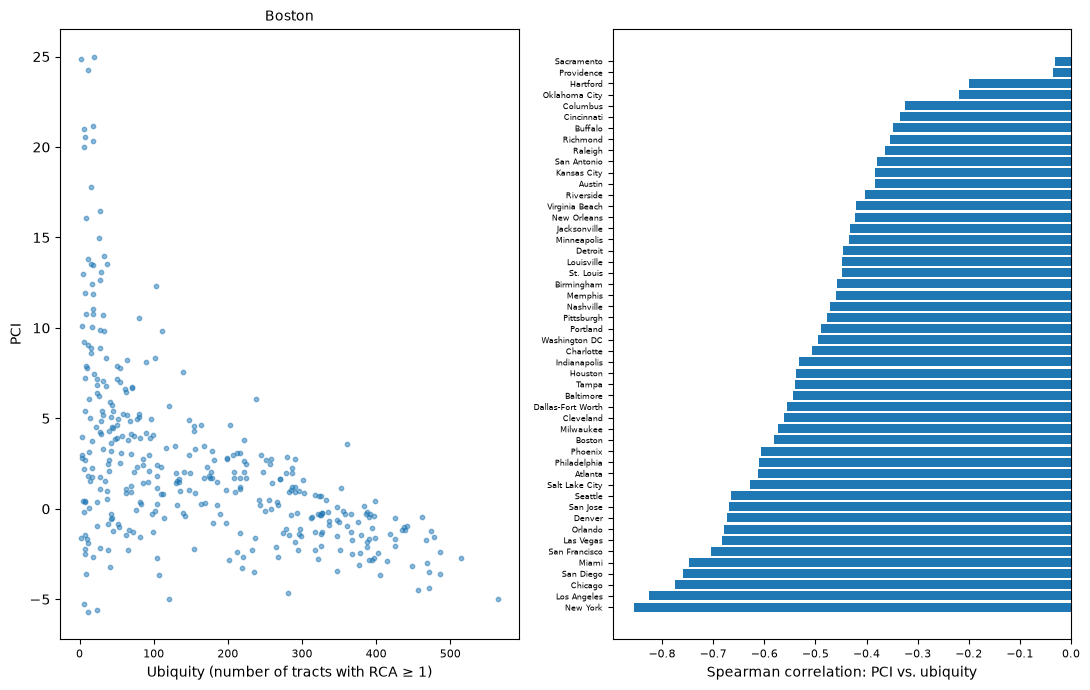

In [13]:
# ── plot: Boston (scatter) and all cities (bars) ────────────────────────────
g = cat_final[cat_final["cbsacode"] == CBSA]

fig, axes = plt.subplots(1, 2, figsize=(11, 7), gridspec_kw={"width_ratios": [1, 1]})
axes[0].scatter(g["ubiquity"], g["pci"], s=10, alpha=0.5, color="tab:blue")
axes[0].set_xlabel("Ubiquity (number of tracts with RCA ≥ 1)", fontsize=FS)
axes[0].set_ylabel("PCI", fontsize=FS)
axes[0].set_title(city_name(CBSA), fontsize=FS)
axes[1].barh(pci_ubi.index, pci_ubi.values, color="tab:blue")
axes[1].set_xlabel("Spearman correlation: PCI vs. ubiquity", fontsize=FS)
axes[1].tick_params(axis="y", labelsize=FS4)
for ax in axes:
    ax.tick_params(axis="x", labelsize=FS2)
fig.tight_layout()

PCI is moderately negatively associated with amenity ubiquity across metropolitan areas (mean Spearman ρ = -0.50; median = -0.49). The relationship is consistently negative but varies considerably across cities (ρ = -0.85 to -0.03), indicating that amenity complexity is related to rarity but is not simply equivalent to it.

## Part 2b. Single-city ECI vs. pooled ECI

The single-city ECI compares tracts inside one city; the pooled ECI puts all ~38,000 tracts in one calculation.
For every city we correlate the two values of its tracts.
By default this uses the saved files (all categories). Set `RUN_POOLED = True` to recompute the pooled ECI with the filtered categories.

In [14]:
# ── single-city vs. pooled ECI ──────────────────────────────────────────────
RUN_POOLED = True

tract_city = all_counts[["census_tract_ID", "cbsacode"]].drop_duplicates()

if RUN_POOLED:
    df = counts_final[["census_tract_ID", "POI_clean_category", "nr_amenities"]].copy()
    df["time"] = 0
    cols_input = {"time": "time", "loc": "census_tract_ID",
                  "prod": "POI_clean_category", "val": "nr_amenities"}
    res = ecomplexity(df, cols_input, check_logsupermodularity=False, verbose=False)
    pooled = res[["census_tract_ID", "eci"]].drop_duplicates()
    single = eci_final
else:
    pooled = pd.read_parquet(PROCESSED + "eci_pooled_top50.parquet")             # LOAD
    single = baseline

pooled = pooled.merge(tract_city, on="census_tract_ID")
single_vs_pooled = compare_eci(single, pooled).rename(index=city_name).sort_values()

print(single_vs_pooled.describe().loc[["mean", "50%", "min", "max"]].round(2))

mean    0.89
50%     0.94
min     0.30
max     0.98
dtype: float64


In [15]:
single_vs_pooled.sort_values().head(10)

Providence        0.300026
Salt Lake City    0.607464
Sacramento        0.634499
Hartford          0.697353
Milwaukee         0.806560
Buffalo           0.816514
San Jose          0.828549
New York          0.831217
Las Vegas         0.849536
Oklahoma City     0.856206
dtype: float64

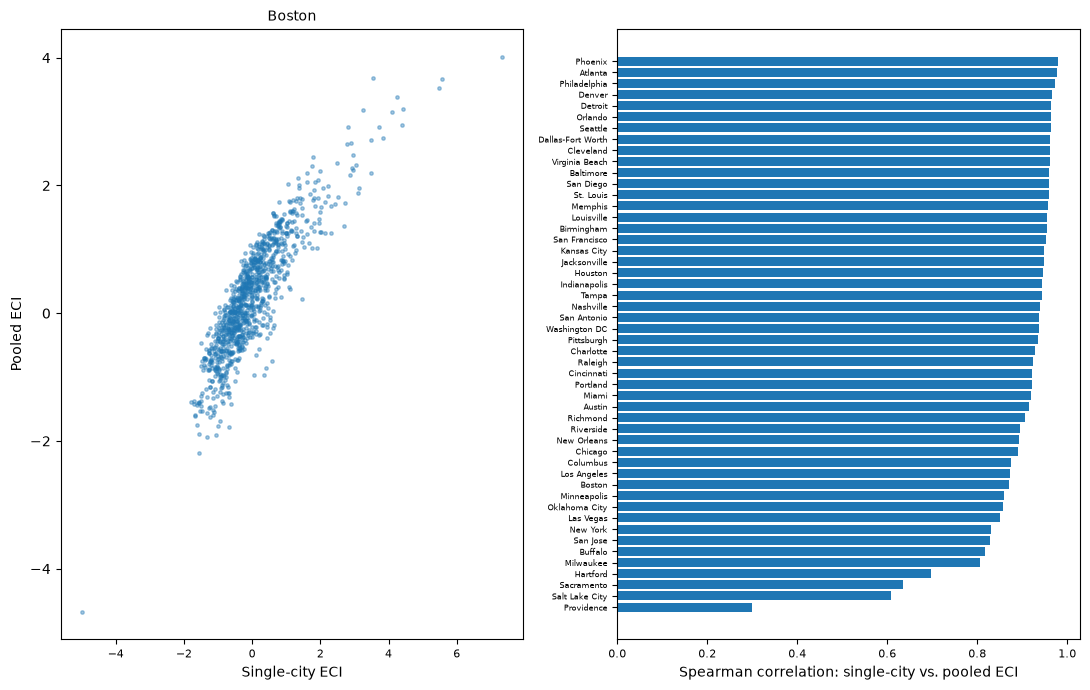

In [16]:
# ── plot: Boston (scatter) and all cities (bars) ────────────────────────────
m = single[single["cbsacode"] == CBSA].merge(pooled, on=["census_tract_ID", "cbsacode"], suffixes=("_single", "_pooled"))

fig, axes = plt.subplots(1, 2, figsize=(11, 7))
axes[0].scatter(m["eci_single"], m["eci_pooled"], s=6, alpha=0.4, color="tab:blue")
axes[0].set_xlabel("Single-city ECI", fontsize=FS)
axes[0].set_ylabel("Pooled ECI", fontsize=FS)
axes[0].set_title(city_name(CBSA), fontsize=FS)
axes[1].barh(single_vs_pooled.index, single_vs_pooled.values, color="tab:blue")
axes[1].set_xlabel("Spearman correlation: single-city vs. pooled ECI", fontsize=FS)
axes[1].tick_params(axis="y", labelsize=FS4)
for ax in axes:
    ax.tick_params(axis="x", labelsize=FS2)
fig.tight_layout()

## Part 2c. Single-city PCI vs. pooled PCI

In [19]:
# ── PCI for each metro separately (already computed in Part 2a) ──────────────
pci_final = cat_final.copy()

print("Metros:", pci_final["cbsacode"].nunique())
print("Rows:", len(pci_final))
pci_final.head()

Metros: 50
Rows: 18276


,POI_clean_category,ubiquity,pci,cbsacode
0,Acupuncture Clinic,118,6.226931,12060
1,Addiction Treatment Center,71,4.919412,12060
2,Adult Store,46,6.396600,12060
3,Advertising Agency,383,-0.570481,12060
4,Agriculture and Forestry Service,223,-3.277274,12060


In [20]:
# ── pooled PCI across all 50 metros (already computed in Part 2b) ────────────
pooled_pci = (
    res[["POI_clean_category", "ubiquity", "pci"]]
    .drop_duplicates("POI_clean_category")
    .rename(columns={"pci": "pci_pooled", "ubiquity": "ubiquity_pooled"})
)

pooled_pci.head()

,POI_clean_category,ubiquity_pooled,pci_pooled
0,Acupuncture Clinic,5968,4.848311
1,Addiction Treatment Center,2672,3.592527
2,Adult Store,1273,5.698158
3,Advertising Agency,13591,-0.566808
4,Agriculture and Forestry Service,5368,-2.150245


In [21]:
# ── single-city PCI vs pooled PCI ─────────────────────────────────────────────
pci_city_vs_pooled = {}

for cbsa, group in pci_final.groupby("cbsacode"):
    merged = group.merge(pooled_pci, on="POI_clean_category", how="inner")
    pci_city_vs_pooled[cbsa] = spearmanr(merged["pci"], merged["pci_pooled"])[0]

pci_city_vs_pooled = pd.Series(pci_city_vs_pooled).rename(index=city_name)

print(pci_city_vs_pooled.describe().loc[["mean", "50%", "min", "max"]].round(2))

mean    0.73
50%     0.76
min     0.32
max     0.89
dtype: float64


In [22]:
pci_city_vs_pooled.sort_values().head(10)

Providence        0.324415
Sacramento        0.397106
Salt Lake City    0.423160
Hartford          0.510951
Milwaukee         0.543810
San Jose          0.583879
Oklahoma City     0.601119
Las Vegas         0.625791
Riverside         0.641858
Buffalo           0.653141
dtype: float64

In [23]:
# ── is the agreement related to the size of the metro? ───────────────────────
n = counts_final.groupby("cbsacode").agg(n_tracts=("census_tract_ID", "nunique"),
                                         n_pois=("nr_amenities", "sum"))
n.index = n.index.map(city_name)

check = pd.concat([single_vs_pooled.rename("eci_agreement"),
                   pci_city_vs_pooled.rename("pci_agreement"), n], axis=1)
check.corr(method="spearman").loc[["eci_agreement", "pci_agreement"], ["n_tracts", "n_pois"]].round(2)

,n_tracts,n_pois
eci_agreement,0.27,0.32
pci_agreement,0.67,0.75


## Conclusion

**Category filtering.** Removing categories present in fewer than 40 of the 50 metros or with fewer than 50 POIs reduces the number of categories from 410 to 370 while keeping 99.97% of all POIs. The tract-level ECI is highly robust to this choice: the within-metro rank correlation with the baseline ECI is 0.99 on average (minimum 0.61 for the most sensitive metro). Even the stricter specification requiring a category to be present in all 50 metros (308 categories) leaves the ECI rankings largely unchanged (mean ρ = 0.98). The POI threshold has no effect at the 10–50 level, so the city-presence criterion does all the filtering. The working specification (370 categories) is therefore a conservative choice, and the results do not depend on it.

**PCI and ubiquity.** Within metros, amenity complexity (PCI) is moderately and consistently negatively related to ubiquity, i.e. the number of tracts specialized in the amenity (mean Spearman ρ = −0.50, range −0.85 to −0.03). Complex amenities tend to be those that few neighborhoods specialize in, but complexity is not simply equivalent to ubiquity, and the strength of the relationship varies considerably across metros.

**Single-city vs. pooled measures.** Single-city and pooled complexity are generally positively aligned. For neighborhoods (ECI), the mean within-metro correlation is 0.89 (median 0.94, minimum 0.30). For amenities (PCI), it is 0.73 (median 0.76, minimum 0.32). The same metros (e.g. Providence, Sacramento, Salt Lake City, Hartford, Milwaukee) show the lowest agreement for both measures. For PCI, agreement increases strongly with metro size (ρ = 0.75 with the number of POIs), which suggests that the low agreement of smaller metros partly reflects noisier estimates rather than only distinctive local amenity structures. For ECI the relationship with size is weaker (ρ = 0.32), so size explains only part of the differences.

**Implications for the next steps.** Because the filtered ECI is nearly identical to the baseline, the 370-category specification can be used in the analysis that follows. The metro-specific results are well suited to within-city comparisons and to analyses with metro fixed effects, while the pooled ECI is better suited to comparisons across metros. Metros with low agreement between the two versions (notably Providence) should be inspected before interpreting their results.